### [GALT] Vežba 3: Raspodela zvezda u Galaksiji

### <font color='yellow'> Ideja vežbe: Određivanje Galaktičkog potencijala i rotacione krive iz sintetičke populacije zvezda. </font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

#### Uvod

U prošloj vežbi, generisali smo sintetičku populaciju zvezda koja prati Salpeterov zakon:
$$\frac{dN}{dM} \propto M^{-\alpha}, \quad \alpha \approx 2.35.$$
U nastavku smo pretpostavili da su zvezde ravnomerno raspoređene u sferi, da bismo analizirali Malmkvisnovu neobjektivnost. Međutim, mi znamo da raspodela zvezda (i generalno materije) u Galaksiji nije uniformna.

Pretpostavimo da je prostorna gustina zvezda opisana eksponencijalnim diskom:

$$
\rho(R,z)=\rho_0\exp(-R/R_d)\exp(-|z|/z_d),
$$

gde su R i z cilindrične koordinate, $R_d$ i $z_d$ skala diska i visinska skala. Ugao $\varphi$ je uniforman na $(0,2\pi)$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

##### <font color="green">1. Semplovati 100 000 zvezda koje prate Salpeterovu IMF. Uzeti da je minimalna masa zvezde 0.08MSun, a maksimalna npr. 200MSun. (Ovo je iz prethodne vežbe.)</font>

In [3]:
random = np.random.default_rng(42)

alfa = 2.35
M_min, M_max = 0.08, 200 # u masama sunca
N = 100000

u = random.random(N)
e = 1 - alfa
M = (M_min**e + u * (M_max**e - M_min**e))**(1/e)

print(M)

[0.24067841 0.12273466 0.34066809 ... 0.14695742 0.08802142 0.57842712]


##### <font color="green">2. Semplovati cilindrične koordinate za svaku zvezdu. (Uzeti, npr. $R_d$ = 3kpc i $z_d$ = 0.2kpc.) Objasniti kako se semplovanje vrši. </font>

In [4]:
Rd = 3
zd = 0.2

R = random.gamma(2, Rd, N)
z = -zd * np.log(1 - random.random(N)) * random.choice([-1, 1], N) #-1, 1 dodato zbog nasumicnog znaka za z


fi = 2*np.pi*random.random(N)
x = R*np.cos(fi)
y = R*np.sin(fi)

print(R)
print(z)


[10.36032129  7.48656658 20.92536276 ...  9.49739133  7.40675685
  8.21504116]
[ 0.23267368  0.44267563  0.14489162 ...  0.18237337  0.24291829
 -0.26334477]


Kako je gustina proizvod 2 funckije gde prvi deo zavisi samo od R, a drugi samo od z, oni se mogu birati nezavisno jedan od drugog. Ako gledamo samo raspodelu po R moramo ukljuciti i zapreminski element te tako dobijamo $p(R)\propto R\,e^{-R/R_d}$ sto je Gamma raspodela. Kod z odradjen je ITS po uzoru na vezbu 2. Ugao fi je tu zato sto je disk simetrican oko ose.

##### <font color="green">3. Prikazati raspodelu zvezda u 3D, kao i (R, z) i (x, y) ravni.</font>

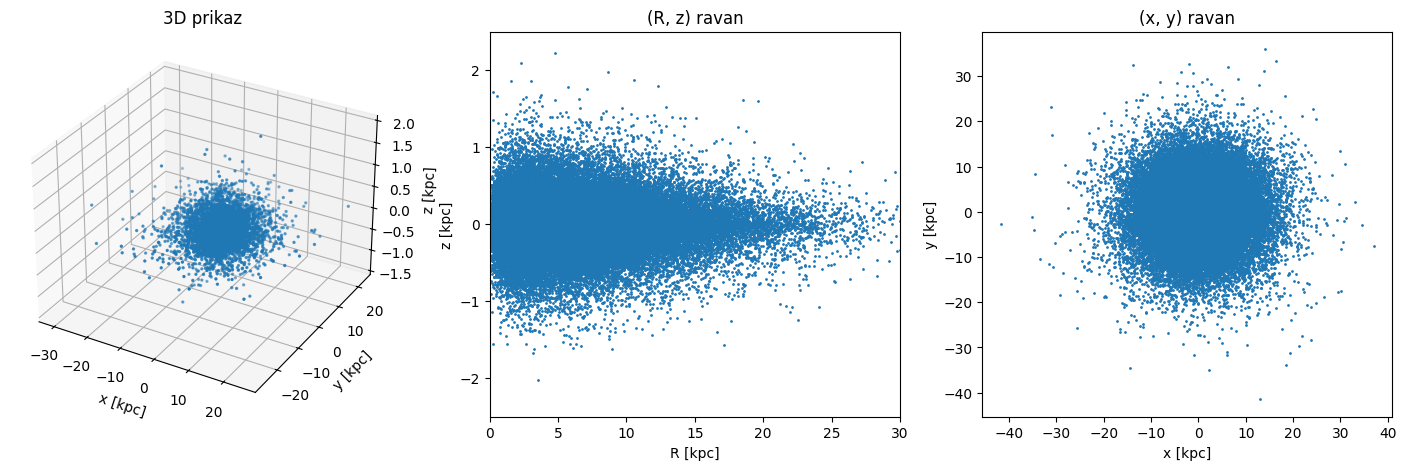

In [14]:
n = 5000 # podskup zvezda za 3D prikaz

fig = plt.figure(figsize=(18,5))

ax = fig.add_subplot(1, 3, 1, projection='3d')
ax.scatter(x[:n], y[:n], z[:n], s=2)
ax.set_xlabel('x [kpc]'); ax.set_ylabel('y [kpc]'); ax.set_zlabel('z [kpc]')
ax.set_title('3D prikaz')

ax = fig.add_subplot(1, 3, 2)
ax.scatter(R, z, s=1)
ax.set_xlim(0, 30); ax.set_ylim(-2.5, 2.5)
ax.set_xlabel('R [kpc]'); ax.set_ylabel('z [kpc]')
ax.set_title('(R, z) ravan')

ax = fig.add_subplot(1, 3, 3)
ax.scatter(x, y, s=1)
ax.set_xlabel('x [kpc]'); ax.set_ylabel('y [kpc]')
ax.set_title('(x, y) ravan')

plt.show()


U (R,z) ravni jasno se vidi da je vecina zvezda koncentrisana oko z=0, a da debljina diska i gustina opadaju sa R. U (x, y) ravni diks je okrugao i najgusci u sredini a redji ka ivicama sto potvrdjuje uniformnu raspodelu zadatu preko ugla fi. U 3d prikazu vidi se da je raspon po z mnogo manji nego raspon po x i y tj. da je disk spljosten.

Potrebno je odraditi normalizaciju, tako da celi disk ima masu $M_{disk}$. Uzeti, npr. $M_{disk}=5\cdot 10^{10}M_\odot$. Dakle, ako integralimo prethodno zadatku gustinu po zapremini, možemo da odredimo vrednost $\rho_0$. 

##### <font color="green">4. Izračunati $\rho_0$.</font>

In [16]:
M_disk = 5e10 # u masama sunca

# M_disk = integral(ro)dV = ro0 * 2pi * Rd^2 * 2 zd
ro0 = M_disk / (4*np.pi*Rd**2*zd)
print(f"ro0 = {ro0:.3e} Msun/kpc^3")

ro0 = 2.210e+09 Msun/kpc^3


Dalje, koristeći Poasonovu jednačinu: 

$$\nabla^2 \Phi = 4\pi G\rho$$

možemo da odredimo Galaktički potencijal koji odgovara zadatoj raspodeli gustine.

Poasonova jednačina u cilindričnim koordinatama:

$$ \frac{1}{R}\frac{\partial}{\partial R}
\left(R\frac{\partial\Phi}{\partial R}\right)
+\frac{\partial^2\Phi}{\partial z^2}
=4\pi G\rho(R,z).
$$

Koristiti metodu konačnih razlika na dvodimenzionalnoj mreži $(R,z)$, za oblast $0\leq R\leq30\mathrm{kpc}$ i $-10\leq z\leq10\mathrm{kpc}$.

Primeniti sledeće granične uslove:

Na spoljnim granicama oblasti pretpostaviti da se potencijal približava potencijalu tačkaste mase ukupne mase diska:

$$
\Phi(R,z)=-\frac{GM}{\sqrt{R^2+z^2}}.
$$

Na osi simetrije (R=0) primeniti uslov:

$$
\left.\frac{\partial\Phi}{\partial R}\right|_{R=0}=0.
$$

U nastavku je napisana funkcija solve_poisson koja numerički rešava ovaj problem.

In [17]:
def solve_poisson(rho, R, z, M, G):

    # broj tačaka numeričke mreže u R i z pravcu
    NR = len(R)
    NZ = len(z)

    # korak
    dR = R[1] - R[0]
    dz = z[1] - z[0]

    # na spoljnim granicama unapred zadajemo potencijal, pa ne moramo da ga racunamo kao nepoznatu
    nR = NR - 1
    nZ = NZ - 2

    # ukupan broj tačaka u kojima računamo vrednosti potencijala
    N = nR * nZ

    # 2D mrežu (i,j) preslikavamo u 1D indeks k, jer sistem rešavamo u obliku matrice A i vektora b
    def idx(i, j):
        return i * nZ + (j - 1)

    # formiramo praznu matricu A
    # koristimo lil_matrix jer je većina elemenata matrice nula
    A = lil_matrix((N, N))

    # desna strana Poasonove jednacine: 4*pi*G*rho
    b = (4 * np.pi * G * rho[:nR, 1:-1]).ravel().copy()

    # kreiramo 2D mrežu koordinata
    RR, ZZ = np.meshgrid(R, z, indexing="ij")

    # na spoljnim granicama oblasti potencijal aproksimiramo potencijalom tačkaste mase ukupne mase M
    # kao što piše iznad u graničnim uslovima, imamo ovo +1e-30 da ne bi došlo do deljenja sa 0 
    phi_boundary = -G * M / np.sqrt(RR**2 + ZZ**2 + 1e-30)

    # prolazimo kroz sve tačke u kojima je potencijal nepoznat
    for i in range(nR):
        for j in range(1, NZ - 1):

            # 1D indeks trenutne tačke
            k = idx(i, j)

            # -----------------------------------------
            # DRUGI IZVOD PO Z
            # -----------------------------------------

            # Drugi izvod po z aproksimiramo metodom konacnih razlika:
            #
            # d^2Phi/dz^2 ~
            # (Phi[i,j+1] - 2*Phi[i,j] + Phi[i,j-1]) / dz^2

            A[k, k] += -2 / dz**2

            # dodajemo doprinose susednih tačaka u z pravcu
            for jj in (j - 1, j + 1):

                if 1 <= jj <= NZ - 2:

                    # ako je susedna tačka unutar oblasti
                    # nepoznatih vrednosti, dodajemo je u matricu A
                    A[k, idx(i, jj)] += 1 / dz**2

                else:

                    # ako je susedna tačka na granici oblasti, njen potencijal je vec poznat
                    b[k] -= phi_boundary[i, jj] / dz**2

            # -----------------------------------------
            # RADIJALNI DEO POASONOVE JEDNACINE
            # -----------------------------------------

            if i == 0:

                # Na osi R = 0 izraz 1/R nije definisan.
                # Zbog osne simetrije važi dPhi/dR = 0 na R = 0.
                # Koristimo posebnu aproksimaciju radijalnog operatora
                # na samoj osi.

                A[k, k] += -4 / dR**2
                A[k, idx(1, j)] += 4 / dR**2

            else:

                # Za R > 0 koristimo aproksimaciju konačnih razlika
                Ri = R[i]

                # koeficijenti uz potencijal u susednim radijalnim tackama R[i+1] i R[i-1].
                cp = 1 / dR**2 + 1 / (2 * Ri * dR)
                cm = 1 / dR**2 - 1 / (2 * Ri * dR)

                # koeficijent uz potencijal u trenutnoj tački
                A[k, k] += -2 / dR**2

                # doprinos unutršnje susedne tacke R[i-1]
                A[k, idx(i - 1, j)] += cm

                # doprinos susedne tacke R[i+1]
                if i + 1 < nR:

                    #ako je tačka unutar oblasti nepoznatih vrednosti, njen doprinos dodajemo u matricu A
                    A[k, idx(i + 1, j)] += cp

                else:

                    #  ako je susedna tačka na granici oblasti, njen potencijal je vec poznat
                    b[k] -= cp * phi_boundary[i + 1, j]

    # -----------------------------------------
    # REŠAVANJE SISTEMA LINEARNIH JEDNAČINA
    # -----------------------------------------

    # Nakon diskretizacije Poasonove jednačine dobijamo sistem:
    #
    # A * Phi = b
    #
    # Funkcija spsolve numerički rešava ovaj sistem.
    # Rezultat je vektor vrednosti potencijala.
    #
    # zatim ga vraćamo u oblik 2D mreže (nR, nZ).
    phi_inner = spsolve(A.tocsr(), b).reshape(nR, nZ)

    # -----------------------------------------
    # REKONSTRUKCIJA MATRICE POTENCIJALA
    # -----------------------------------------

    # kreiramo matricu u kojoj ce biti sačuvane vrednosti potencijala u svim tačkama prvobitne mreže
    Phi = np.empty((NR, NZ))

    # na spoljašnjim granicama imamo unapred zadate vrednosti potencijala
    Phi[-1, :] = phi_boundary[-1, :]
    Phi[:, 0] = phi_boundary[:, 0]
    Phi[:, -1] = phi_boundary[:, -1]

    # unutrašnje vrednosti popunjavamo numeričkim rešenjem
    Phi[:nR, 1:-1] = phi_inner

    # funkcija vraća matricu gravitacionog potencijala Phi(R,z)
    return Phi

Pogledati kako funkcija radi i ne koristiti ju kao black-box. 

##### <font color="green">5. Pozivajući solve_possion funkciju, rešiti Poasonovu jednačinu i prikazati 2D mapu potencijala.</font>

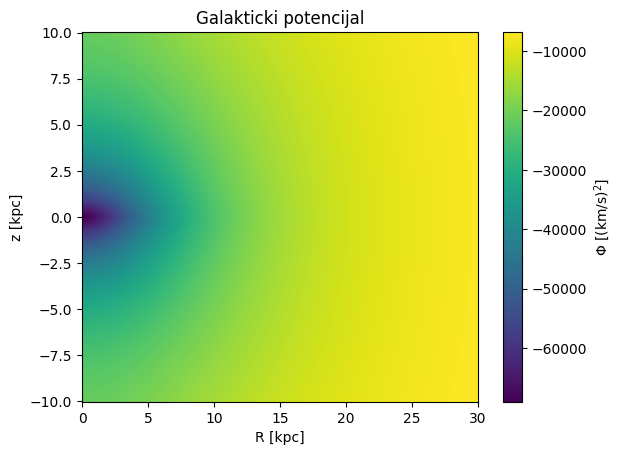

In [20]:
G = 4.30091e-6 # gravitaciona konst. izrazena u kpc(km/s)^2/Msun

# konstrukcija grida za resavanje jne i grafik
R_grid = np.linspace(0, 30, 301)
z_grid = np.linspace(-10, 10, 401)
RR, ZZ = np.meshgrid(R_grid, z_grid, indexing='ij')

ro = ro0 * np.exp(-RR/Rd) * np.exp(-np.abs(ZZ)/zd)

fi = solve_poisson(ro, R_grid, z_grid, M_disk, G)

plt.Figure(figsize=(8,6))
plt.pcolormesh(R_grid, z_grid, fi.T)
plt.colorbar(label=r'$\Phi$ [(km/s)$^2$]')
plt.xlabel('R [kpc]')
plt.ylabel('z [kpc]')
plt.title('Galakticki potencijal')
plt.show()

Potencijal negativan i najdublji u centru diska tj na R=0 i z=0, a raste ka spolja

Ako znamo potencijal, brzinu rotacije možemo odrediti koristeći izraz:
$$ \frac{v_c^2}{R} = \frac{\delta\Phi}{\delta R} $$

##### <font color="green">6. Koristeći prethodni izraz, prikazati rotacionu krivu. </font>

C:\Users\aleks\AppData\Local\Temp\ipykernel_16528\2945746076.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


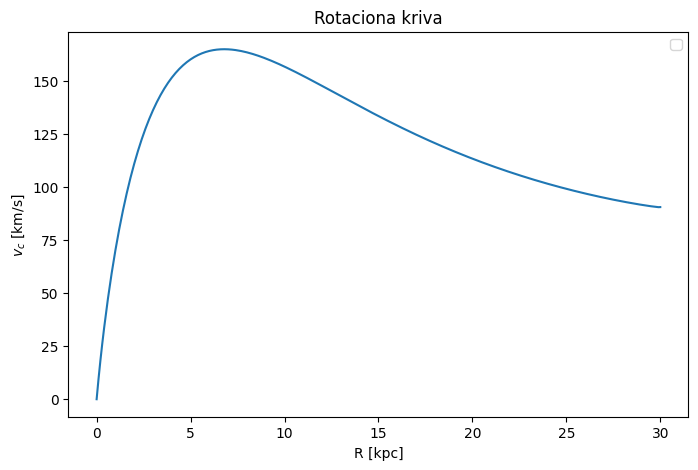

In [25]:
iz = len(z_grid)//2
vc = np.sqrt(R_grid * np.gradient(fi[:, iz], R_grid))

plt.figure(figsize=(8,5))
plt.plot(R_grid, vc)
plt.title('Rotaciona kriva')
plt.xlabel('R [kpc]')
plt.ylabel(r'$v_c$ [km/s]')
plt.legend()
plt.show()

Brzina rotacije raste u unutrasnjem delu diska, 6-7kpc, a zatim opada. 

Za razliku od izmerene rotacione krive Mlecnog puta (slika 6.11 iz knjige Opsta astrofizika), koja ostaje ravna na velikim R, ovde nema ravnog dela krive. Razlog je sto potencijal racunamo samo iz zvezdanog diska ($5\cdot10^{10}M_\odot$), bez tamne materije, ciji halo dodaje masu na velikim radijusima i "podize" krivu. Takodje nema centralnog ispupcenja (bulge), koje bi povecalo brzinu na malim R. Zato je kriva nize od posmatrane.

##### <font color="green">7. Odrediti brzinu Sunca iz ove rotacione krive i uporediti sa prihvaćenom vrednošću. </font> 

In [23]:
R_sun = 8.2 
v_sun = np.interp(R_sun, R_grid, vc)

print(f"v_sun = {v_sun} km/s")

v_sun = 162.8803536567574 km/s


Dobijena brzina Sunca iz modela je znatno manja od prihvacene vrednosti od $\approx 250$ km/s. Razlog toga je sto je model nepotpun gde nemamo bulge i tamnu materiju

##### <font color="green">8. Kako se menja rotaciona kriva ako je ukupna masa diska dva puta veća, z nepromenjene vrednosti $R_d$ i $z_d$. </font> 

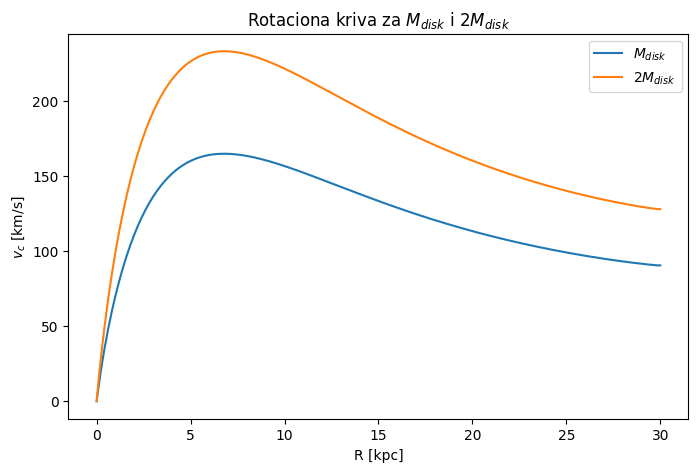

In [29]:
ro2 = 2*ro
fi2 = solve_poisson(ro2, R_grid, z_grid, 2*M_disk, G)

vc2 = np.sqrt(R_grid * np.gradient(fi2[:, iz], R_grid))

plt.figure(figsize=(8,5))
plt.plot(R_grid, vc, label=r'$M_{disk}$')
plt.plot(R_grid, vc2, label=r'$2M_{disk}$')
plt.title(r'Rotaciona kriva za $M_{disk}$ i $2M_{disk}$')
plt.xlabel('R [kpc]')
plt.ylabel(r'$v_c$ [km/s]')
plt.legend()
plt.show()

Kada se ukupna masa diska udvostruci cela rotaciona kriva se podize, dok joj oblik ostaje isti.

Razlog je linearnost Poasonove jednacine: ako je $\rho\to2\rho$ (i $M\to2M$ u graničnom uslovu), onda je $\Phi\to2\Phi$, pa je $v_c^2=R\,\frac{\partial\Phi}{\partial R}\to2v_c^2$, odnosno $v_c\to\sqrt2\,v_c$. Numericki je odnos krivih $1.414$ za svako R

Brzina Sunca bi u tom slucaju bila $\approx230$ km/s, sto je blizu prihvacenoj vrednosti. To znaci da bi masa unutar orbite Sunca morala biti oko dva puta veca od mase samog zvezdanog diska, a taj dodatak u stvarnoj Galaksiji dolazi od bulge-a i tamne materije.